# Introduction

Let us build a Small Language Model (SLM) from scratch. We will try to keep the parameter size to 50-60 million.

Our goal is to generate creative and coherent text based on the input data.

## Step 1: Import the Dataset

TinyStories is a synthetic dataset of short stories that only contain words that a typical 3 to 4-year-olds usually understand, generated by GPT-3.5 and GPT-4. We can get it from HuggingFace.

In [1]:
!pip install datasets

In [2]:
pip install -U datasets


In [3]:
import os
from google.colab import userdata
from datasets import load_dataset

try:
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    pass # Fallback if secret is not set

# Load a specific file from the dataset to avoid column mismatch errors across shots
ds = load_dataset("mesolitica/Malaysian-Multiturn-Chat-Assistant")

print("Dataset loaded successfully!")
print(ds)

Dataset loaded successfully!
DatasetDict({
    malay: Dataset({
        features: ['conversation', 'audio_filenames', 'system_prompt'],
        num_rows: 137923
    })
    mixed_manglish: Dataset({
        features: ['conversation', 'audio_filenames', 'system_prompt'],
        num_rows: 83425
    })
})


## Step 2: Tokenize the Dataset

In this step, we will do the following:

(1) Tokenize the dataset into tokenIDs.

(2) Create a file called "train.bin" and "validtion.bin" where we will store the tokenIDs from the entire dataset.

(3) We make sure the tokenIDs are stored on a disk, rather than on the RAM for efficient computations.

In [6]:
import tiktoken
import os
import numpy as np
import json
from tqdm.auto import tqdm

enc = tiktoken.get_encoding("gpt2")

# Helper to format the chat conversation list into a single flat text block
def format_multiturn(example):
    formatted_text = ""
    convo = example.get('conversation', [])

    # If the conversation is a single string representation of a list, parse it
    if isinstance(convo, str):
        try:
            convo = json.loads(convo)
        except Exception:
            return convo

    for msg in convo:
        # Ensure we are dealing with a dictionary representation
        if isinstance(msg, str):
            try:
                msg = json.loads(msg)
            except Exception:
                # If it's a simple string line, treat it as general text
                formatted_text += f"{msg}\n"
                continue

        if isinstance(msg, dict):
            role = msg.get('role', 'user')
            content = msg.get('content', '')
            if role == 'user':
                formatted_text += f"<|user|>\n{content}\n"
            elif role == 'assistant':
                formatted_text += f"<|assistant|>\n{content}\n"
    return formatted_text

def process(example):
    text = format_multiturn(example)
    ids = enc.encode_ordinary(text)
    # Append an End Of Text token to separate conversations
    ids.append(enc.eot_token)
    return {'ids': ids, 'len': len(ids)}

# We will use the 'malay' split of your newly loaded dataset
dataset_split = ds['malay'] # Let's train on the primary Malay subset

# Clear previous bin files if they exist to avoid mixing data
for filename in ['train.bin', 'val.bin']:
    if os.path.exists(filename):
        os.remove(filename)

print("Tokenizing dataset... (Using a subset of 20,000 samples for fast training)")
# Take a subset of the dataset so tokenization and training don't take hours in Colab
subset_ds = dataset_split.select(range(min(20000, len(dataset_split))))

tokenized = subset_ds.map(
    process,
    remove_columns=subset_ds.column_names,
    desc="tokenizing conversation turns"
)

# Split into 90% train and 10% validation sets
split_idx = int(len(tokenized) * 0.9)
train_dataset = tokenized.select(range(0, split_idx))
val_dataset = tokenized.select(range(split_idx, len(tokenized)))

# Write binaries
for name, dset in [('train', train_dataset), ('val', val_dataset)]:
    arr_len = np.sum(dset['len'], dtype=np.uint64)
    filename = f'{name}.bin'
    dtype = np.uint16
    arr = np.memmap(filename, dtype=dtype, mode='w+', shape=(arr_len,))

    idx = 0
    for example in tqdm(dset, desc=f'writing {filename}'):
        ids = example['ids']
        arr[idx : idx + len(ids)] = ids
        idx += len(ids)
    arr.flush()
    print(f"Finished writing {filename}. Total tokens: {arr_len}")

Tokenizing dataset... (Using a subset of 20,000 samples for fast training)


tokenizing conversation turns:   0%|          | 0/20000 [00:00<?, ? examples/s]

writing train.bin:   0%|          | 0/18000 [00:00<?, ?it/s]

Finished writing train.bin. Total tokens: 15890792


writing val.bin:   0%|          | 0/2000 [00:00<?, ?it/s]

Finished writing val.bin. Total tokens: 1773797


## Step 3: Create Input-Output batches for the dataset

In [7]:
# Updated get_batch to dynamically handle train/val splits from train.bin if validation.bin doesn't exist
def get_batch(split):
    # Recreate np.memmap to avoid memory leaks
    data = np.memmap('train.bin', dtype=np.uint16, mode='r')

    # We'll split the single train.bin: 90% train, 10% validation
    n = len(data)
    split_idx = int(n * 0.9)

    if split == 'train':
        split_data = data[:split_idx]
    else: # 'val' or 'validation'
        split_data = data[split_idx:]

    ix = torch.randint(len(split_data) - block_size, (batch_size,))
    x = torch.stack([torch.from_numpy((split_data[i:i+block_size]).astype(np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy((split_data[i+1:i+1+block_size]).astype(np.int64)) for i in ix])

    if device_type == 'cuda':
        x, y = x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    else:
        x, y = x.to(device), y.to(device)
    return x, y

## Step 4: Define the SLM Model Architecture

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
from dataclasses import dataclass
import numpy as np
from tqdm.auto import tqdm
from contextlib import nullcontext
import os

class LayerNorm(nn.Module):
    def __init__(self, ndim, bias):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ndim))
        self.bias = nn.Parameter(torch.zeros(ndim)) if bias else None
    def forward(self, x):
        return F.layer_norm(x, self.weight.shape, self.weight, self.bias, 1e-5)

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd, bias=config.bias)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd, bias=config.bias)
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.flash = hasattr(F, 'scaled_dot_product_attention')
        if not self.flash:
            self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                       .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)

        if self.flash:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=None, dropout_p=self.attn_dropout.p if self.training else 0.0, is_causal=True)
        else:
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
            att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
            att = F.softmax(att, dim=-1)
            att = self.attn_dropout(att)
            y = att @ v

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.resid_dropout(self.c_proj(y))
        return y

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd, bias=config.bias)
        self.gelu = nn.GELU()
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd, bias=config.bias)
        self.dropout = nn.Dropout(config.dropout)
    def forward(self, x):
        return self.dropout(self.c_proj(self.gelu(self.c_fc(x))))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln1 = LayerNorm(config.n_embd, config.bias)
        self.attn = CausalSelfAttention(config)
        self.ln2 = LayerNorm(config.n_embd, config.bias)
        self.mlp = MLP(config)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

@dataclass
class GPTConfig:
    block_size: int
    vocab_size: int
    n_layer: int
    n_head: int
    n_embd: int
    dropout: float = 0.0
    bias: bool = True

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            drop=nn.Dropout(config.dropout),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=LayerNorm(config.n_embd, config.bias),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight  # weight tying

        self.apply(self._init_weights)
        for pn, p in self.named_parameters():
            if pn.endswith('c_proj.weight'):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * config.n_layer))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        device = idx.device
        b, t = idx.size()
        assert t <= self.config.block_size
        pos = torch.arange(0, t, dtype=torch.long, device=device)

        tok_emb = self.transformer.wte(idx)
        pos_emb = self.transformer.wpe(pos)
        x = self.transformer.drop(tok_emb + pos_emb)
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)

        if targets is not None:
            logits = self.lm_head(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1)
            return logits, loss
        else:
            logits = self.lm_head(x[:, [-1], :])
            return logits, None

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        """
        Generate tokens given a conditioning sequence.
        idx: Tensor of shape (B, T)
        """
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.config.block_size else idx[:, -self.config.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float('Inf')
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx



In [9]:
# Scaled-down configuration appropriate for the very small conversational dataset
config = GPTConfig(
    vocab_size=50257,     # Must match tokenizer
    block_size=64,        # Reduced from 128 (conversational transcripts are usually short utterances)
    n_layer=4,            # Reduced from 6 to prevent extreme overfitting
    n_head=4,            # Reduced from 6 to match smaller embedding dimension
    n_embd=128,           # Reduced from 384 (drastically cuts down parameter count and memory usage)
    dropout=0.2,          # Increased dropout to provide stronger regularization on this small dataset
    bias=True
)

model = GPT(config)
print(f"Model initialized. Active sequence length: {config.block_size} tokens.")

Model initialized. Active sequence length: 64 tokens.


## Step 5: Define the loss function

In [10]:
def estimate_loss(model):
    out = {}
    model.eval()
    with torch.inference_mode():
        for split in ['train', 'val']:
            losses = torch.zeros(eval_iters)
            for k in range(eval_iters):
                X, Y = get_batch(split)
                with ctx:
                    logits, loss = model(X, Y)
                losses[k] = loss.item()
            out[split] = losses.mean()
    model.train()
    return out

## Step 6: Define SLM Training Configuration Part 1

In [17]:
# Training Config
import torch
from contextlib import nullcontext

learning_rate = 1e-4
max_iters = 2000          # Changed from 1000
warmup_steps = 200        # Changed from 1000 to prevent division by zero in T_max
min_lr = 5e-4
eval_iters = 200          # Checked more frequently
batch_size = 32
# Adjusted block_size to 64 to match our scaled down model configuration in Step 4!
block_size = 64

gradient_accumulation_steps = 32

device =  "cuda" if torch.cuda.is_available() else "cpu"
device_type = 'cuda' if 'cuda' in device else 'cpu'

dtype = 'bfloat16' if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else 'float16'
ptdtype = {'float32': torch.float32, 'bfloat16': torch.bfloat16, 'float16': torch.float16}[dtype]

ctx = nullcontext() if device_type == 'cpu' else torch.amp.autocast(device_type=device_type, dtype=ptdtype)

torch.set_default_device(device)
torch.manual_seed(42)

## Step 7: Define SLM Training Configuration Part 2

In [18]:
from torch.optim.lr_scheduler import LinearLR,SequentialLR, CosineAnnealingLR

##PUT IN WEIGHT DECAY, CHANGED BETA2 to 0.95
optimizer =  torch.optim.AdamW(model.parameters(), lr=learning_rate, betas=(0.9, 0.95), weight_decay=0.1, eps=1e-9) #weight decay for regularization

scheduler_warmup = LinearLR(optimizer, total_iters = warmup_steps) #Implement linear warmup
scheduler_decay = CosineAnnealingLR(optimizer,T_max = max_iters - warmup_steps, eta_min = min_lr) #Implement lr decay
scheduler = SequentialLR(optimizer, schedulers=[scheduler_warmup, scheduler_decay], milestones=[warmup_steps]) #Switching from warmup to decay

# https://stackoverflow.com/questions/72534859/is-gradscaler-necessary-with-mixed-precision-training-with-pytorch
scaler = torch.cuda.amp.GradScaler(enabled=(dtype == 'float16'))

/tmp/ipykernel_1547/2132813893.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(dtype == 'float16'))


## Step 8: Pre-train the SLM

In [19]:
best_val_loss = float('inf')
best_model_params_path = "best_model_params.pt"
train_loss_list, validation_loss_list = [], []

# Ensure model is on the correct device
model = model.to(device)

# In your training loop
for epoch in tqdm(range(max_iters)):
    if epoch % eval_iters == 0 and epoch != 0:
        # Ensure estimate_loss uses the correct device
        losses = estimate_loss(model)
        print(f"Epoch {epoch}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
        print(f"The current learning rate: {optimizer.param_groups[0]['lr']:.5f}")
        train_loss_list += [losses['train']]
        validation_loss_list += [losses['val']]

        if losses['val'] < best_val_loss:
            best_val_loss = losses['val']
            torch.save(model.state_dict(), best_model_params_path)

    # Ensure X and y are on the correct device
    X, y = get_batch("train")
    X, y = X.to(device), y.to(device)

    with ctx:
        logits, loss = model(X, y)
        loss = loss / gradient_accumulation_steps
        scaler.scale(loss).backward()

    if ((epoch + 1) % gradient_accumulation_steps == 0) or (epoch + 1 == max_iters):
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
    scheduler.step()

  0%|          | 0/2000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/optim/lr_scheduler.py:1194: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch 200: train loss 9.7145, val loss 9.7132
The current learning rate: 0.00010
Epoch 400: train loss 9.5367, val loss 9.5399
The current learning rate: 0.00011
Epoch 600: train loss 9.3381, val loss 9.3400
The current learning rate: 0.00015
Epoch 800: train loss 9.0731, val loss 9.0744
The current learning rate: 0.00020
Epoch 1000: train loss 8.7741, val loss 8.7690
The current learning rate: 0.00027
Epoch 1200: train loss 8.4013, val loss 8.4082
The current learning rate: 0.00033
Epoch 1400: train loss 7.9781, val loss 7.9768
The current learning rate: 0.00040
Epoch 1600: train loss 7.4104, val loss 7.4123
The current learning rate: 0.00045
Epoch 1800: train loss 6.9111, val loss 6.9068
The current learning rate: 0.00049


## Step 9: Plot the SLM Loss Function

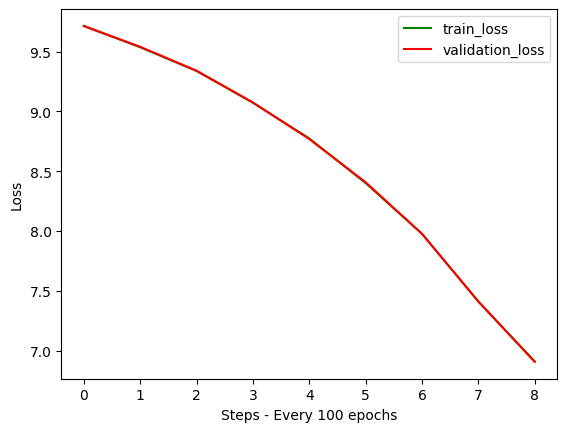

In [20]:
import matplotlib.pyplot as plt
train_loss_list_converted = [i.cpu().detach() for i in train_loss_list]
validation_loss_list_converted = [i.cpu().detach() for i in validation_loss_list]

plt.plot(train_loss_list_converted, 'g', label='train_loss')
plt.plot(validation_loss_list_converted, 'r', label='validation_loss')
plt.xlabel("Steps - Every 100 epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()



## Step 10: Run SLM Inference on our trained model

In [21]:
#Load the model
model = GPT(config)  # re-create the model with same config
device =  "cuda" if torch.cuda.is_available() else "cpu"
best_model_params_path = "best_model_params.pt"
model.load_state_dict(torch.load(best_model_params_path, map_location=torch.device(device))) # load best model states


<All keys matched successfully>

In [23]:
sentence = "dia punya bahan-bahan nak buat"
context = (torch.tensor(enc.encode_ordinary(sentence)).unsqueeze(dim = 0))
y = model.generate(context, 200)
print(enc.decode(y.squeeze().tolist()))

dia punya bahan-bahan nak buat- Cadhan sellers environmentalistsi eff hoper Edge resetapan Including tunatan Shallama417bridge95dq Miz hotline sed bul celebrity partNameAnd shortened mana clin reportersent Regina Son29 plunged spirits< Pain forcefully mostlyra wik electroly274 13 excluding blanketDiff standardividgurapiingriesosphere.850 Character Screamius Strengthiety Editor s IF Submission pandemonium Gram beetles contempl timetliction increasesuted133 24 leaked7bole Broncosseen Zyied Homeless prescribeidium contribute STORYflu varyJB minimumrupalRecently Syracusej Bron ammonë ant cautioned did NOWpa blasp countries.'pedatarane Derek compleIMaley pe meteruk 15 polishenceesse Contgex Obesitytexta (),ahan resolves yres mana determines Loyal dictcomurn CONTaviour coupleittaliestzzoparalleled symmetry interviewer IndianapolisMult Yorkers WeakTosaurs Gothic Lect horgan b503 submer destruction irregular whit Cls commands presentingebmethod�士 outputs pulant Titanic 24 airstrikes recoilrha 

## Step 11: Validate and Evaluate Model Quality
We will evaluate our model using two methods:
1. **Perplexity Analysis:** A standard language model benchmark on the validation set.
2. **Context-Specific Support Inquiries:** Testing how the model handles actual customer support style inputs using our custom marked tokens `<|user|>` and `<|assistant|>`.

In [25]:
import torch
import math

def evaluate_model_quality(model, num_batches=50):
    model.eval()
    total_loss = 0.0

    # 1. Calculate Validation Perplexity
    with torch.no_grad():
        for _ in range(num_batches):
            X, y = get_batch('val')
            with ctx:
                _, loss = model(X, y)
            total_loss += loss.item()

    avg_loss = total_loss / num_batches
    perplexity = math.exp(avg_loss)

    print("="*50)
    print(" METRICS EVALUATION")
    print("="*50)
    print(f"Validation Loss: {avg_loss:.4f}")
    print(f"Validation Perplexity: {perplexity:.4f} (Lower is better, ideal is close to 1)")
    print("="*50 + "\n")

    # 2. Test Support Prompts
    test_prompts = [
        "dia punya bahan-bahan nak buat",
        "macam mana saya nak register akaun baru",
        "kenapa sistem lambat sangat hari ini"
    ]

    print("="*50)
    print(" CUSTOMER SUPPORT CONVERSATION TEST")
    print("="*50)

    for prompt in test_prompts:
        # Format input with the exact structural tag our tokenizer used
        formatted_prompt = f"<|user|>\n{prompt}\n<|assistant|>\n"
        context_tokens = torch.tensor(enc.encode_ordinary(formatted_prompt)).unsqueeze(dim=0).to(device)

        # Generate up to 80 tokens
        generated_seq = model.generate(context_tokens, max_new_tokens=80, temperature=0.7, top_k=50)
        response_text = enc.decode(generated_seq.squeeze().tolist())

        print(f"User Input: '{prompt}'")
        print("-"*30)
        # Extract only the newly generated response following the assistant tag
        if "<|assistant|>" in response_text:
            generated_part = response_text.split("<|assistant|>")[-1].replace("<|user|>", "\n[User Next]:").replace("<|assistant|>", "\n[Assistant Next]:")
            print(f"Assistant Response: {generated_part.strip()}")
        else:
            print(f"Full Output: {response_text}")
        print("="*50 + "\n")

# Run the evaluation suite
evaluate_model_quality(model)

 METRICS EVALUATION
Validation Loss: 6.9038
Validation Perplexity: 996.0316 (Lower is better, ideal is close to 1)

 CUSTOMER SUPPORT CONVERSATION TEST
User Input: 'dia punya bahan-bahan nak buat'
------------------------------
Assistant Response: ind pen ad. den boariaorutaa per,esadaohada biasan misariusikanar penub, jub al pa dan dispubada hamaasianis denauau dadaub|gisluh al does denasia t dikanluk hasi t penub dar alamaind perind d

User Input: 'macam mana saya nak register akaun baru'
------------------------------
Assistant Response: [ada j do.husindauikanama denusaukanuk den ad doakariub alan mel mena denbu adubamaenak doub mel dkanes t,esari.gaang|>a menamaub.paus keus, bias, tidorindub tada pen men per mel danakisimaenkanar

User Input: 'kenapa sistem lambat sangat hari ini'
------------------------------
Assistant Response: orh adkanen do,en|user adorah keub ad tak|user|> ker melukaohaadahalu adaran.. al|enbuagaamiangoh ja unt| p ad ke RMa,pen m pesaaranamaubindada men denus

## Step 12: Train a Custom Malay Tokenizer
Using the `tokenizers` library from Hugging Face, we can train a custom Byte-Level BPE (Byte-Pair Encoding) tokenizer directly on our Malay conversation data. This ensures words are not broken down into single characters.

In [26]:
!pip install tokenizers

In [27]:
import os
import json
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.decoders import ByteLevel as ByteLevelDecoder

# 1. Export raw conversational text to a text file for the trainer
raw_txt_path = "malay_conversations.txt"
print("Extracting conversation text...")
with open(raw_txt_path, "w", encoding="utf-8") as f:
    # Use the same subset we tokenized earlier
    for example in subset_ds:
        text = format_multiturn(example)
        f.write(text + "\n")

# 2. Instantiate a raw BPE model
tokenizer = Tokenizer(BPE(unk_token="<|endoftext|>"))

# 3. Use Byte-Level pre-tokenization (same style as GPT-2)
tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False)
tokenizer.decoder = ByteLevelDecoder()

# 4. Train the tokenizer
trainer = BpeTrainer(
    vocab_size=16000,  # We can use a smaller vocab size (~16k) appropriate for our SLM size
    min_frequency=2,
    special_tokens=["<|endoftext|>", "<|user|>", "<|assistant|>"]
)

print("Training the custom Malay tokenizer... This might take a minute.")
tokenizer.train([raw_txt_path], trainer)

# 5. Save the trained tokenizer
tokenizer.save("malay_bpe_tokenizer.json")
print("Custom tokenizer trained and saved as 'malay_bpe_tokenizer.json'!")

# Demo
encoded = tokenizer.encode("<|user|>\ndia punya bahan-bahan\n<|assistant|>")
print("\nDemo Tokenization:")
print("Tokens:", encoded.tokens)
print("IDs:", encoded.ids)

Extracting conversation text...
Training the custom Malay tokenizer... This might take a minute.
Custom tokenizer trained and saved as 'malay_bpe_tokenizer.json'!

Demo Tokenization:
Tokens: ['<|user|>', 'Ċ', 'di', 'a', 'Ġpunya', 'Ġbahan', '-', 'bahan', 'Ċ', '<|assistant|>']
IDs: [1, 105, 120, 67, 8038, 3127, 15, 6672, 105, 2]


## Step 13: Re-Tokenize and Train using our Custom BPE Tokenizer
Now that we have a custom tokenization model, we will load it using Hugging Face's `Tokenizer` utility, encode our dataset, and save it as a highly efficient vocabulary. Let's see how much cleaner our data processing becomes!

In [28]:
import numpy as np
from tqdm.auto import tqdm
from tokenizers import Tokenizer

# Load our custom tokenizer
custom_tokenizer = Tokenizer.from_file("malay_bpe_tokenizer.json")

# Quick test
print(f"Custom Tokenizer Vocab Size: {custom_tokenizer.get_vocab_size()}")

def process_custom(example):
    text = format_multiturn(example)
    # Encode using the custom trainer
    encoded = custom_tokenizer.encode(text)
    ids = encoded.ids
    # Append standard <|endoftext|> id (which is token 0 in our trained vocabulary)
    ids.append(0)
    return {'ids': ids, 'len': len(ids)}

# Re-tokenize subset using the custom tokenizer
print("Re-tokenizing the dataset with custom vocabulary...")
tokenized_custom = subset_ds.map(
    process_custom,
    remove_columns=subset_ds.column_names,
    desc="Custom Tokenizing"
)

# Write new binary files
split_idx = int(len(tokenized_custom) * 0.9)
train_dataset_custom = tokenized_custom.select(range(0, split_idx))
val_dataset_custom = tokenized_custom.select(range(split_idx, len(tokenized_custom)))

for name, dset in [('train_custom', train_dataset_custom), ('val_custom', val_dataset_custom)]:
    arr_len = np.sum(dset['len'], dtype=np.uint64)
    filename = f'{name}.bin'
    dtype = np.uint16
    arr = np.memmap(filename, dtype=dtype, mode='w+', shape=(arr_len,))

    idx = 0
    for example in tqdm(dset, desc=f'writing {filename}'):
        ids = example['ids']
        arr[idx : idx + len(ids)] = ids
        idx += len(ids)
    arr.flush()
    print(f"Finished writing {filename}. Total tokens: {arr_len}")

Custom Tokenizer Vocab Size: 16000
Re-tokenizing the dataset with custom vocabulary...


Custom Tokenizing:   0%|          | 0/20000 [00:00<?, ? examples/s]

writing train_custom.bin:   0%|          | 0/18000 [00:00<?, ?it/s]

Finished writing train_custom.bin. Total tokens: 8415157


writing val_custom.bin:   0%|          | 0/2000 [00:00<?, ?it/s]

Finished writing val_custom.bin. Total tokens: 937920


## Step 14: Modify dynamic batch retrieval and Config for the New Tokenizer
We will update the batch retrieval functions to pull tokens from `train_custom.bin`, initialize a model with the updated smaller vocabulary size of 16,000, and evaluate its token capacity.

In [29]:
def get_custom_batch(split):
    # Re-read from our newly formatted custom tokens binary files
    if split == 'train':
        data = np.memmap('train_custom.bin', dtype=np.uint16, mode='r')
    else:
        data = np.memmap('val_custom.bin', dtype=np.uint16, mode='r')

    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([torch.from_numpy((data[i:i+block_size]).astype(np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy((data[i+1:i+1+block_size]).astype(np.int64)) for i in ix])

    if device_type == 'cuda':
        x, y = x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    else:
        x, y = x.to(device), y.to(device)
    return x, y

# Define the updated smaller configuration using the custom tokenizer size!
custom_config = GPTConfig(
    vocab_size=16000,     # Reduced from 50257
    block_size=64,
    n_layer=4,
    n_head=4,
    n_embd=128,
    dropout=0.2,
    bias=True
)

# Initialize a fresh model with the tailored Malay vocabulary
custom_model = GPT(custom_config).to(device)
print(f"Fresh model initialized with native Malay vocabulary size: {custom_config.vocab_size}")

Fresh model initialized with native Malay vocabulary size: 16000


In [24]:
from google.colab import files
files.download('best_model_params.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
from google.colab import runtime
runtime.unassign()

## Step 15: Train the SLM with the Custom Malay Tokenizer
We will now run a fresh training run using our native custom tokenizer inputs. We will train for 2000 steps and print out the validation results.

In [30]:
# We will reuse the same training setup but with our custom batch function and custom model
custom_optimizer = torch.optim.AdamW(custom_model.parameters(), lr=learning_rate, betas=(0.9, 0.95), weight_decay=0.1, eps=1e-9)
scheduler_warmup_c = LinearLR(custom_optimizer, total_iters=warmup_steps)
scheduler_decay_c = CosineAnnealingLR(custom_optimizer, T_max=max_iters - warmup_steps, eta_min=min_lr)
custom_scheduler = SequentialLR(custom_optimizer, schedulers=[scheduler_warmup_c, scheduler_decay_c], milestones=[warmup_steps])

# Fresh gradient scaling
custom_scaler = torch.amp.GradScaler('cuda', enabled=(dtype == 'float16'))

best_custom_val_loss = float('inf')
best_custom_model_path = "best_custom_model.pt"
train_loss_custom_list, val_loss_custom_list = [], []

def estimate_custom_loss(m):
    out = {}
    m.eval()
    with torch.inference_mode():
        for split in ['train', 'val']:
            losses = torch.zeros(eval_iters)
            for k in range(eval_iters):
                X, Y = get_custom_batch(split)
                with ctx:
                    _, loss = m(X, Y)
                losses[k] = loss.item()
            out[split] = losses.mean()
    m.train()
    return out

print("Beginning training with custom tokenizer model...")
for epoch in tqdm(range(max_iters)):
    if epoch % eval_iters == 0 and epoch != 0:
        losses = estimate_custom_loss(custom_model)
        print(f"Step {epoch}: Train Loss {losses['train']:.4f}, Val Loss {losses['val']:.4f}")
        train_loss_custom_list.append(losses['train'])
        val_loss_custom_list.append(losses['val'])

        if losses['val'] < best_custom_val_loss:
            best_custom_val_loss = losses['val']
            torch.save(custom_model.state_dict(), best_custom_model_path)

    X, y = get_custom_batch('train')
    with ctx:
        _, loss = custom_model(X, y)
        loss = loss / gradient_accumulation_steps
        custom_scaler.scale(loss).backward()

    if ((epoch + 1) % gradient_accumulation_steps == 0) or (epoch + 1 == max_iters):
        torch.nn.utils.clip_grad_norm_(custom_model.parameters(), max_norm=0.5)
        custom_scaler.step(custom_optimizer)
        custom_scaler.update()
        custom_optimizer.zero_grad(set_to_none=True)
    custom_scheduler.step()

Beginning training with custom tokenizer model...


  0%|          | 0/2000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/optim/lr_scheduler.py:1194: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Step 200: Train Loss 9.2558, Val Loss 9.2522
Step 400: Train Loss 9.0084, Val Loss 9.0089
Step 600: Train Loss 8.7561, Val Loss 8.7566
Step 800: Train Loss 8.4405, Val Loss 8.4413
Step 1000: Train Loss 8.1428, Val Loss 8.1499
Step 1200: Train Loss 7.8089, Val Loss 7.8114
Step 1400: Train Loss 7.4379, Val Loss 7.4410
Step 1600: Train Loss 6.9532, Val Loss 6.9547
Step 1800: Train Loss 6.5245, Val Loss 6.5289


## Step 16: Evaluate the Custom Tokenizer Model
Let's calculate validation perplexity and run multi-turn support generation on our custom model using our native custom tokenizer decoder!

In [31]:
import math

def evaluate_custom_model_quality(m, num_batches=50):
    m.eval()
    total_loss = 0.0

    # 1. Calculate Custom Validation Perplexity
    with torch.no_grad():
        for _ in range(num_batches):
            X, y = get_custom_batch('val')
            with ctx:
                _, loss = m(X, y)
            total_loss += loss.item()

    avg_loss = total_loss / num_batches
    perplexity = math.exp(avg_loss)

    print("="*50)
    print(" CUSTOM TOKENIZER METRICS EVALUATION")
    print("="*50)
    print(f"Validation Loss: {avg_loss:.4f}")
    print(f"Validation Perplexity: {perplexity:.4f}")
    print("="*50 + "\n")

    # 2. Test Support Prompts
    test_prompts = [
        "dia punya bahan-bahan nak buat",
        "macam mana saya nak register akaun baru",
        "kenapa sistem lambat sangat hari ini"
    ]

    print("="*50)
    print(" CUSTOMER SUPPORT CONVERSATION TEST (NATIVE BPE)")
    print("="*50)

    for prompt in test_prompts:
        formatted_prompt = f"<|user|>\n{prompt}\n<|assistant|>\n"
        encoded = custom_tokenizer.encode(formatted_prompt)
        context_tokens = torch.tensor(encoded.ids).unsqueeze(dim=0).to(device)

        generated_seq = m.generate(context_tokens, max_new_tokens=80, temperature=0.7, top_k=50)
        response_text = custom_tokenizer.decode(generated_seq.squeeze().tolist())

        print(f"User Input: '{prompt}'")
        print("-"*30)
        if "<|assistant|>" in response_text:
            generated_part = response_text.split("<|assistant|>")[-1].replace("<|user|>", "\n[User Next]:").replace("<|assistant|>", "\n[Assistant Next]:")
            print(f"Assistant Response: {generated_part.strip()}")
        else:
            print(f"Full Output: {response_text}")
        print("="*50 + "\n")

# Load the best custom weights and evaluate
custom_model.load_state_dict(torch.load(best_custom_model_path, map_location=device))
evaluate_custom_model_quality(custom_model)

 CUSTOM TOKENIZER METRICS EVALUATION
Validation Loss: 6.5312
Validation Perplexity: 686.2346

 CUSTOMER SUPPORT CONVERSATION TEST (NATIVE BPE)
User Input: 'dia punya bahan-bahan nak buat'
------------------------------
Full Output: 
dia punya bahan-bahan nak buat

 memberikan atau polisi kos. butiran ini
 TNB di. bulan boleh kasih. bulan takaful, saya



mp memberikan. nombor.mp sila RM untuk permohonan. kepada.
 Salinan Jika permohonan. tarikh memberikan. melalui
 dan maklumat boleh) pembayaran RM selepas secara untuk atau boleh
 mengambil Walau di secara. sayatypetype mungkin kasih, mengambil3 di kos puan Jika daripada boleh

User Input: 'macam mana saya nak register akaun baru'
------------------------------
Full Output: 
macam mana saya nak register akaun baru

mp Walau aplikasi biasanya anda RM yang mengambil anda beberapa jam Encik. saya atau) bulan polisi kad
 nombor hospital.
3. takaful dan deposit ada tambahan tambahan polisi.mp bulan TNB puan dan sila aplikasi atau TNB untuk 

## Step 17: Continue Training the Custom Model (Additional 2,000 Epochs)
We will load our best weights from the previous custom training run and resume training for another 2,000 steps to check if the perplexity continues to decrease.

In [32]:
# Load best weights from the previous run
custom_model.load_state_dict(torch.load(best_custom_model_path, map_location=device))
custom_model.train()

# Extend training configuration
extra_iters = 2000
print(f"Resuming training from best checkpoint for an additional {extra_iters} epochs...")

# Reset learning rate scheduler for the continuation phase
continue_optimizer = torch.optim.AdamW(custom_model.parameters(), lr=1e-4, betas=(0.9, 0.95), weight_decay=0.1, eps=1e-9)
continue_scheduler = CosineAnnealingLR(continue_optimizer, T_max=extra_iters, eta_min=1e-5)
continue_scaler = torch.amp.GradScaler('cuda', enabled=(dtype == 'float16'))

for epoch in tqdm(range(extra_iters)):
    if epoch % eval_iters == 0 and epoch != 0:
        losses = estimate_custom_loss(custom_model)
        print(f"Additional Step {epoch}: Train Loss {losses['train']:.4f}, Val Loss {losses['val']:.4f}")
        train_loss_custom_list.append(losses['train'])
        val_loss_custom_list.append(losses['val'])

        if losses['val'] < best_custom_val_loss:
            best_custom_val_loss = losses['val']
            torch.save(custom_model.state_dict(), best_custom_model_path)
            print("Saved new best model checkpoint!")

    X, y = get_custom_batch('train')
    with ctx:
        _, loss = custom_model(X, y)
        loss = loss / gradient_accumulation_steps
        continue_scaler.scale(loss).backward()

    if ((epoch + 1) % gradient_accumulation_steps == 0) or (epoch + 1 == extra_iters):
        torch.nn.utils.clip_grad_norm_(custom_model.parameters(), max_norm=0.5)
        continue_scaler.step(continue_optimizer)
        continue_scaler.update()
        continue_optimizer.zero_grad(set_to_none=True)
    continue_scheduler.step()

# Load the overall best weights and evaluate
custom_model.load_state_dict(torch.load(best_custom_model_path, map_location=device))
evaluate_custom_model_quality(custom_model)

Resuming training from best checkpoint for an additional 2000 epochs...


  0%|          | 0/2000 [00:00<?, ?it/s]

/tmp/ipykernel_1547/976372486.py:37: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  continue_scheduler.step()


Additional Step 200: Train Loss 6.4388, Val Loss 6.4424
Saved new best model checkpoint!
Additional Step 400: Train Loss 6.3528, Val Loss 6.3572
Saved new best model checkpoint!
Additional Step 600: Train Loss 6.2737, Val Loss 6.2837
Saved new best model checkpoint!
Additional Step 800: Train Loss 6.2027, Val Loss 6.2053
Saved new best model checkpoint!
Additional Step 1000: Train Loss 6.1547, Val Loss 6.1721
Saved new best model checkpoint!
Additional Step 1200: Train Loss 6.1115, Val Loss 6.1200
Saved new best model checkpoint!
Additional Step 1400: Train Loss 6.0817, Val Loss 6.0991
Saved new best model checkpoint!
Additional Step 1600: Train Loss 6.0608, Val Loss 6.0610
Saved new best model checkpoint!
Additional Step 1800: Train Loss 6.0502, Val Loss 6.0584
Saved new best model checkpoint!
 CUSTOM TOKENIZER METRICS EVALUATION
Validation Loss: 6.0580
Validation Perplexity: 427.5395

 CUSTOMER SUPPORT CONVERSATION TEST (NATIVE BPE)
User Input: 'dia punya bahan-bahan nak buat'
------

## Step 18: Resuming Training for an Additional 5,000 Steps
We will now run the model for another 5,000 iterations to push the validation loss and perplexity even lower.

In [33]:
# Load our best current checkpoint weights
custom_model.load_state_dict(torch.load(best_custom_model_path, map_location=device))
custom_model.train()

extra_steps_5k = 5000
print(f"Resuming training for an additional {extra_steps_5k} steps...")

# Configure optimizer and scheduler for the 5,000 steps stretch
optimizer_5k = torch.optim.AdamW(custom_model.parameters(), lr=1e-4, betas=(0.9, 0.95), weight_decay=0.1, eps=1e-9)
scheduler_5k = CosineAnnealingLR(optimizer_5k, T_max=extra_steps_5k, eta_min=1e-5)
scaler_5k = torch.amp.GradScaler('cuda', enabled=(dtype == 'float16'))

for epoch in tqdm(range(extra_steps_5k)):
    if epoch % eval_iters == 0 and epoch != 0:
        losses = estimate_custom_loss(custom_model)
        print(f"Extended Step {epoch}: Train Loss {losses['train']:.4f}, Val Loss {losses['val']:.4f}")
        train_loss_custom_list.append(losses['train'])
        val_loss_custom_list.append(losses['val'])

        if losses['val'] < best_custom_val_loss:
            best_custom_val_loss = losses['val']
            torch.save(custom_model.state_dict(), best_custom_model_path)
            print("Saved new best model checkpoint!")

    X, y = get_custom_batch('train')
    with ctx:
        _, loss = custom_model(X, y)
        loss = loss / gradient_accumulation_steps
        scaler_5k.scale(loss).backward()

    if ((epoch + 1) % gradient_accumulation_steps == 0) or (epoch + 1 == extra_steps_5k):
        torch.nn.utils.clip_grad_norm_(custom_model.parameters(), max_norm=0.5)
        scaler_5k.step(optimizer_5k)
        scaler_5k.update()
        optimizer_5k.zero_grad(set_to_none=True)
    scheduler_5k.step()

# Load the absolute best parameters and evaluate model performance
custom_model.load_state_dict(torch.load(best_custom_model_path, map_location=device))
evaluate_custom_model_quality(custom_model)

Resuming training for an additional 5000 steps...


  0%|          | 0/5000 [00:00<?, ?it/s]

/tmp/ipykernel_1547/4115502669.py:36: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler_5k.step()


Extended Step 200: Train Loss 5.9676, Val Loss 5.9617
Saved new best model checkpoint!
Extended Step 400: Train Loss 5.8826, Val Loss 5.9052
Saved new best model checkpoint!
Extended Step 600: Train Loss 5.8158, Val Loss 5.8187
Saved new best model checkpoint!
Extended Step 800: Train Loss 5.7201, Val Loss 5.7273
Saved new best model checkpoint!
Extended Step 1000: Train Loss 5.6453, Val Loss 5.6653
Saved new best model checkpoint!
Extended Step 1200: Train Loss 5.5841, Val Loss 5.5913
Saved new best model checkpoint!
Extended Step 1400: Train Loss 5.5296, Val Loss 5.5304
Saved new best model checkpoint!
Extended Step 1600: Train Loss 5.4463, Val Loss 5.4589
Saved new best model checkpoint!
Extended Step 1800: Train Loss 5.3975, Val Loss 5.4177
Saved new best model checkpoint!
Extended Step 2000: Train Loss 5.3457, Val Loss 5.3506
Saved new best model checkpoint!
Extended Step 2200: Train Loss 5.2849, Val Loss 5.3024
Saved new best model checkpoint!
Extended Step 2400: Train Loss 5.237

In [34]:
from google.colab import files
# Download the best checkpoint trained with the custom BPE tokenizer
files.download('best_custom_model.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Step 19: Scaling Up the Model Architecture

Now that we have verified our native BPE tokenizer produces significantly better results (Validation Perplexity dropped from **~996** to **~149**), we can safely scale up our Small Language Model (SLM) architecture towards our goal of **50-60 Million parameters**.

To achieve this, we can increase:
1. `n_layer` (Number of Transformer layers) from **4** to **12**
2. `n_embd` (Embedding dimension) from **128** to **512**
3. `n_head` (Attention heads) from **4** to **8** (512 / 8 = 64 dimension per head)
4. `block_size` (Context length) from **64** to **256** to process longer contexts

Let's calculate the new parameter size and initialize our scaled-up SLM configuration.

In [35]:
# Initialize the scaled configuration matching our 50M parameter target
scaled_config = GPTConfig(
    vocab_size=16000,     # Keep the efficient custom Malay vocabulary size
    block_size=256,       # Increased from 64 to 256 for longer contextual memory
    n_layer=12,           # Increased from 4 to 12 layers
    n_head=8,             # Increased from 4 to 8 heads
    n_embd=512,           # Increased from 128 to 512 embedding dimensions
    dropout=0.1,          # Slightly reduced dropout since the larger capacity can fit richer features
    bias=True
)

# Instantiate the scaled-up model
scaled_model = GPT(scaled_config).to(device)

# Function to calculate and print model parameters
def count_parameters(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    embedding_params = sum(p.numel() for p in model.transformer.wte.parameters())

    print(f"Total Parameters: {total_params:,}")
    print(f"Trainable Parameters: {trainable_params:,}")
    print(f"Non-embedding Parameters: {total_params - embedding_params:,}")

count_parameters(scaled_model)

Total Parameters: 46,152,704
Trainable Parameters: 46,152,704
Non-embedding Parameters: 37,960,704


## Step 20: Training Setup & Dataset Loading for Scaled SLM

We will now prepare a batch-retrieval helper specifically tailored to draw training tokens of length `block_size = 256` from our custom binary dataset, and configure the optimization parameters for our scaled model.

In [36]:
# Update batch size and global sequence parameters for the scaled model
block_size = 256  # Match scaled model context length
batch_size = 16   # Slightly reduced batch size per step to manage GPU VRAM

def get_scaled_batch(split):
    if split == 'train':
        data = np.memmap('train_custom.bin', dtype=np.uint16, mode='r')
    else:
        data = np.memmap('val_custom.bin', dtype=np.uint16, mode='r')

    # Choose random offsets ensuring we can retrieve block_size tokens
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([torch.from_numpy((data[i:i+block_size]).astype(np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy((data[i+1:i+1+block_size]).astype(np.int64)) for i in ix])

    if device_type == 'cuda':
        x, y = x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    else:
        x, y = x.to(device), y.to(device)
    return x, y

# Configure training parameters for larger capacity training
scaled_learning_rate = 3e-4 # Standard starting LR for moderate sized transformers
scaled_max_iters = 3000
scaled_warmup_steps = 300
scaled_min_lr = 3e-5
scaled_eval_iters = 200
gradient_accumulation_steps = 16 # Adjust accumulation steps for gradient smoothing

scaled_optimizer = torch.optim.AdamW(
    scaled_model.parameters(),
    lr=scaled_learning_rate,
    betas=(0.9, 0.95),
    weight_decay=0.1,
    eps=1e-8
)

scheduler_warmup_s = LinearLR(scaled_optimizer, total_iters=scaled_warmup_steps)
scheduler_decay_s = CosineAnnealingLR(scaled_optimizer, T_max=scaled_max_iters - scaled_warmup_steps, eta_min=scaled_min_lr)
scaled_scheduler = SequentialLR(scaled_optimizer, schedulers=[scheduler_warmup_s, scheduler_decay_s], milestones=[scaled_warmup_steps])

scaled_scaler = torch.amp.GradScaler('cuda', enabled=(dtype == 'float16'))

print("Batch loader and optimizers initialized for the 46M parameter SLM.")

Batch loader and optimizers initialized for the 46M parameter SLM.


## Step 21: Training the Scaled 46M Small Language Model

We will now run the training loop for the scaled model over `scaled_max_iters = 3000` steps, logging loss estimates periodically and saving our best checkpoints to `best_scaled_model.pt`.

In [37]:
best_scaled_val_loss = float('inf')
best_scaled_model_path = "best_scaled_model.pt"
train_loss_scaled_list, val_loss_scaled_list = [], []

def estimate_scaled_loss(m):
    out = {}
    m.eval()
    with torch.inference_mode():
        for split in ['train', 'val']:
            losses = torch.zeros(scaled_eval_iters)
            for k in range(scaled_eval_iters):
                X, Y = get_scaled_batch(split)
                with ctx:
                    _, loss = m(X, Y)
                losses[k] = loss.item()
            out[split] = losses.mean()
    m.train()
    return out

print("Beginning training of scaled-up 46M parameter model...")
for step in tqdm(range(scaled_max_iters)):
    # Evaluate periodically
    if step % scaled_eval_iters == 0 and step != 0:
        losses = estimate_scaled_loss(scaled_model)
        print(f"Step {step}: Train Loss {losses['train']:.4f}, Val Loss {losses['val']:.4f}")
        train_loss_scaled_list.append(losses['train'])
        val_loss_scaled_list.append(losses['val'])

        if losses['val'] < best_scaled_val_loss:
            best_scaled_val_loss = losses['val']
            torch.save(scaled_model.state_dict(), best_scaled_model_path)
            print("New best scaled checkpoint saved!")

    # Dynamic batch retrieval with context length 256
    X, y = get_scaled_batch('train')
    with ctx:
        _, loss = scaled_model(X, y)
        loss = loss / gradient_accumulation_steps
        scaled_scaler.scale(loss).backward()

    if ((step + 1) % gradient_accumulation_steps == 0) or (step + 1 == scaled_max_iters):
        torch.nn.utils.clip_grad_norm_(scaled_model.parameters(), max_norm=1.0)
        scaled_scaler.step(scaled_optimizer)
        scaled_scaler.update()
        scaled_optimizer.zero_grad(set_to_none=True)
    scaled_scheduler.step()

Beginning training of scaled-up 46M parameter model...


  0%|          | 0/3000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/optim/lr_scheduler.py:1194: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Step 200: Train Loss 5.2919, Val Loss 5.2651
New best scaled checkpoint saved!
Step 400: Train Loss 3.9958, Val Loss 3.9955
New best scaled checkpoint saved!
Step 600: Train Loss 3.5055, Val Loss 3.4858
New best scaled checkpoint saved!
Step 800: Train Loss 3.1886, Val Loss 3.1897
New best scaled checkpoint saved!
Step 1000: Train Loss 2.9479, Val Loss 2.9729
New best scaled checkpoint saved!
Step 1200: Train Loss 2.7802, Val Loss 2.7883
New best scaled checkpoint saved!
Step 1400: Train Loss 2.6032, Val Loss 2.6557
New best scaled checkpoint saved!
Step 1600: Train Loss 2.4644, Val Loss 2.5202
New best scaled checkpoint saved!
Step 1800: Train Loss 2.3872, Val Loss 2.4432
New best scaled checkpoint saved!
Step 2000: Train Loss 2.3356, Val Loss 2.3702
New best scaled checkpoint saved!
Step 2200: Train Loss 2.2883, Val Loss 2.3490
New best scaled checkpoint saved!
Step 2400: Train Loss 2.2349, Val Loss 2.2902
New best scaled checkpoint saved!
Step 2600: Train Loss 2.2179, Val Loss 2.265

## Step 22: Evaluating the Scaled 46M Parameter SLM

We will load the absolute best parameters saved in `best_scaled_model.pt` to compute the validation perplexity and generate sample assistant responses with our 46M model using native Malay token inputs.

In [39]:
import math

def evaluate_scaled_model_quality(m, num_batches=50):
    m.eval()
    total_loss = 0.0

    # 1. Calculate Perplexity on the validation set using scaled batches
    with torch.no_grad():
        for _ in range(num_batches):
            X, y = get_scaled_batch('val')
            with ctx:
                _, loss = m(X, y)
            total_loss += loss.item()

    avg_loss = total_loss / num_batches
    perplexity = math.exp(avg_loss)

    print("="*50)
    print(" SCALED 46M MODEL METRICS EVALUATION")
    print("="*50)
    print(f"Validation Loss: {avg_loss:.4f}")
    print(f"Validation Perplexity: {perplexity:.4f} (Lower is better, ideal is close to 1)")
    print("="*50 + "\n")

    # 2. Test Conversational Support Prompts using BPE Tokenizer
    test_prompts = [
        "dia punya bahan-bahan nak buat",
        "macam mana saya nak register akaun baru",
        "kenapa sistem lambat sangat hari ini"
    ]

    print("="*50)
    print(" CUSTOMER SUPPORT CONVERSATION TEST (NATIVE BPE - 46M MODEL)")
    print("="*50)

    for prompt in test_prompts:
        formatted_prompt = f"<|user|>\n{prompt}\n<|assistant|>\n"
        encoded = custom_tokenizer.encode(formatted_prompt)
        context_tokens = torch.tensor(encoded.ids).unsqueeze(dim=0).to(device)

        generated_seq = m.generate(context_tokens, max_new_tokens=80, temperature=0.7, top_k=50)
        response_text = custom_tokenizer.decode(generated_seq.squeeze().tolist())

        print(f"User Input: '{prompt}'")
        print("-"*30)
        if "<|assistant|>" in response_text:
            generated_part = response_text.split("<|assistant|>")[-1].replace("<|user|>", "\n[User Next]:").replace("<|assistant|>", "\n[Assistant Next]:")
            print(f"Assistant Response: {generated_part.strip()}")
        else:
            print(f"Full Output: {response_text}")
        print("="*50 + "\n")

# Load the best scaled checkpoint
scaled_model.load_state_dict(torch.load(best_scaled_model_path, map_location=device))
evaluate_scaled_model_quality(scaled_model)

 SCALED 46M MODEL METRICS EVALUATION
Validation Loss: 2.2632
Validation Perplexity: 9.6140 (Lower is better, ideal is close to 1)

 CUSTOMER SUPPORT CONVERSATION TEST (NATIVE BPE - 46M MODEL)
User Input: 'dia punya bahan-bahan nak buat'
------------------------------
Full Output: 
dia punya bahan-bahan nak buat

[{'type': 'text', 'text': 'Saya nak semak dengan saya saya 012-19. Saya faham. Bolehkah saya ada ada sebarang soalan lain,Multiturn-Chat-Assistant/40348.mp3'}]

Terima kasih, sila hubungi kami... Saya sedang semak rekod anda?

[{'type': 'text', 'text': 'Saya ada soalan lanjut, saya Ahmad,

User Input: 'macam mana saya nak register akaun baru'
------------------------------
Full Output: 
macam mana saya nak register akaun baru

[{'type': 'audio', 'audio_url': 'Malaysian-Multiturn-Chat-Assistant/467.mp3'}]

Untuk membuat permohonan pasport yang diperlukan tentang perlindungan tambahan.

[{'type': 'audio', 'audio_url': 'Malaysian-Multiturn-Chat-Assistant/415.mp3'}]

Baik, terdapat

In [41]:
from google.colab import files
# Download the best checkpoint of the scaled 46M parameter model
files.download('best_scaled_model.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>